In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [31]:
df=pd.read_csv(r"/content/Student_Performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [32]:
df.shape

(10000, 6)

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [34]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,7144.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.572788,55.224800
std,2.589309,17.343152,1.695863,2.868633,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [35]:
df.duplicated().sum()

np.int64(132)

In [36]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [37]:
df.nunique()

,0
Hours Studied,9
Previous Scores,60
Extracurricular Activities,2
Sleep Hours,6
Sample Question Papers Practiced,10
Performance Index,91


In [38]:
df['Sample Question Papers Practiced'].unique()

array([ 1.,  2.,  5.,  6., nan,  4.,  3.,  0.,  7.,  8.,  9.])

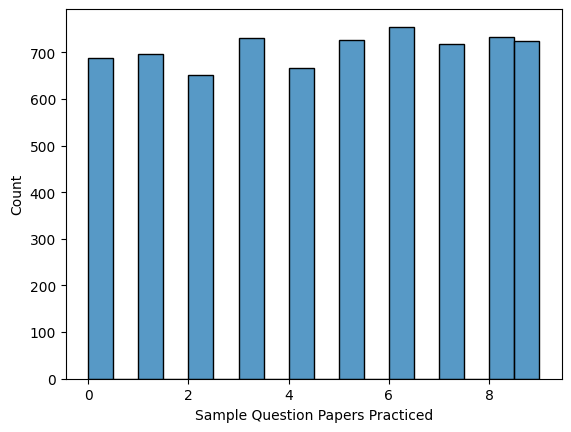

In [39]:
sns.histplot(df['Sample Question Papers Practiced'])
plt.show()


In [40]:
df['Sample Question Papers Practiced'].skew()

np.float64(-0.04148768921377276)

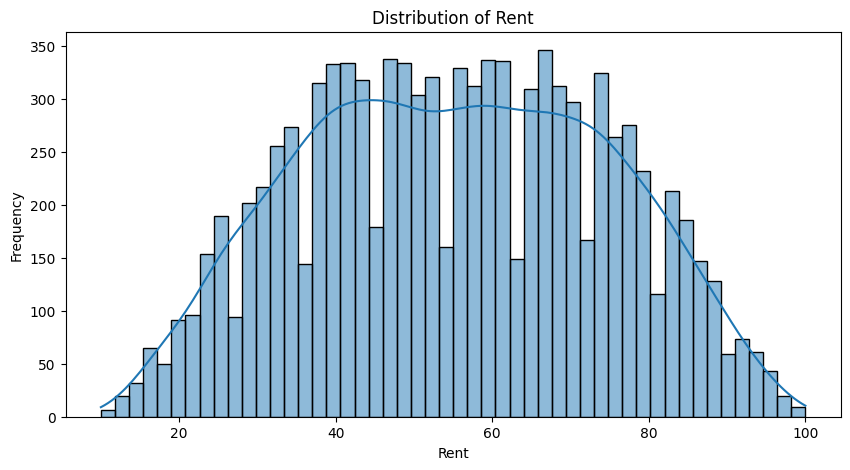

In [41]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Performance Index', bins=50, kde=True)
plt.title('Distribution of Rent')
plt.xlabel('Rent')
plt.ylabel('Frequency')
plt.show()

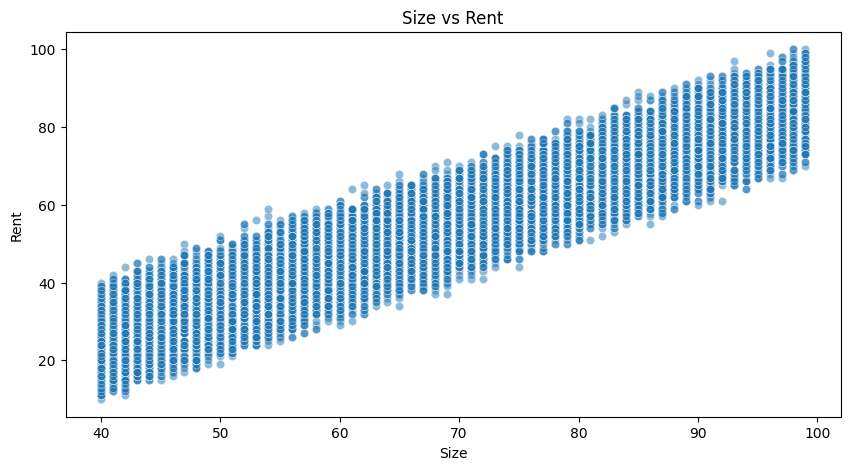

In [42]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Previous Scores', y='Performance Index', alpha=0.5)
plt.title('Size vs Rent')
plt.xlabel('Size')
plt.ylabel('Rent')
plt.show()

(array([1, 2, 3, 4, 5]),
 [Text(1, 0, 'Hours Studied'),
  Text(2, 0, 'Previous Scores'),
  Text(3, 0, 'Sleep Hours'),
  Text(4, 0, 'Sample Question Papers Practiced'),
  Text(5, 0, 'Performance Index')])

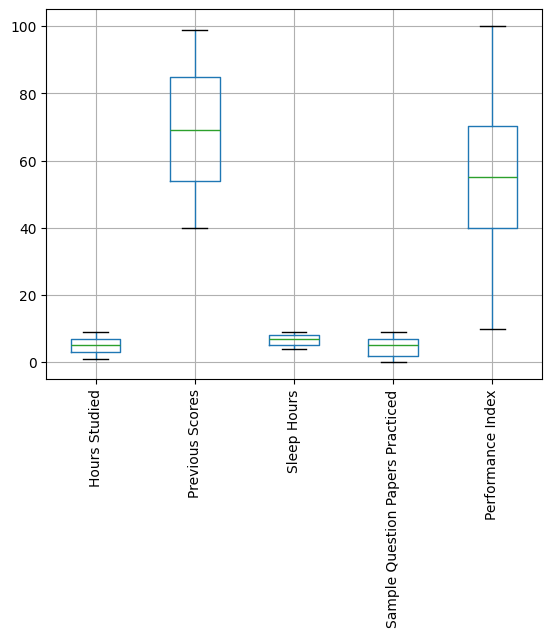

In [43]:
df.boxplot()
plt.xticks(rotation=90)

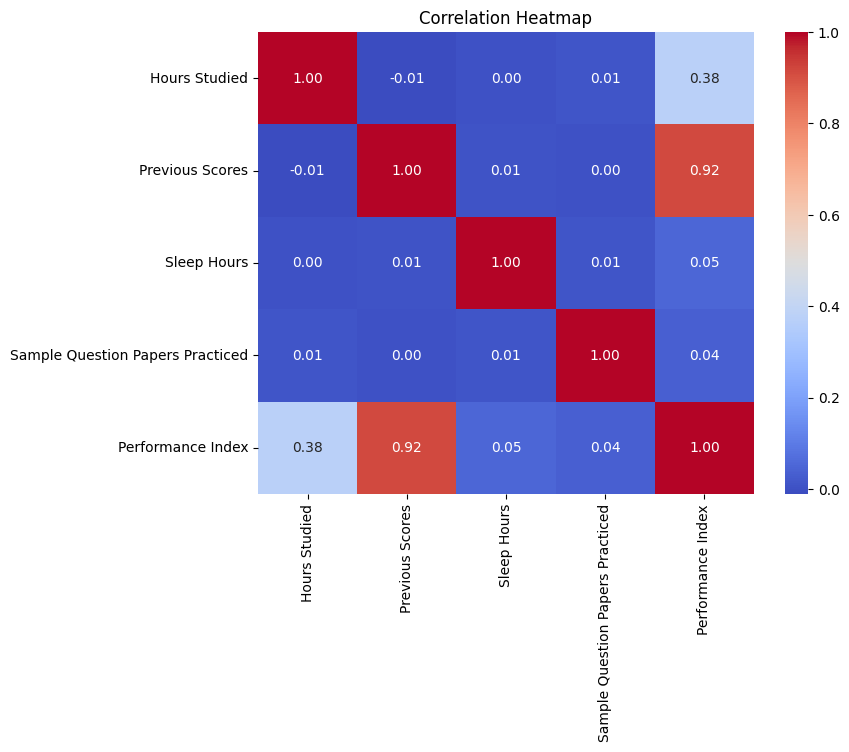

In [44]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [45]:
x=df.drop(columns=['Performance Index'])
y=df['Performance Index']

In [46]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [47]:
list=['Hours Studied','Previous Scores','Sleep Hours','Sample Question Papers Practiced','Sample Question Papers Practiced']
list

['Hours Studied',
 'Previous Scores',
 'Sleep Hours',
 'Sample Question Papers Practiced',
 'Sample Question Papers Practiced']

In [48]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=42,shuffle=True)

In [49]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy='mean')
x_train[['Sample Question Papers Practiced']]=imputer.fit_transform(x_train[['Sample Question Papers Practiced']])
x_test[['Sample Question Papers Practiced']]=imputer.transform(x_test[['Sample Question Papers Practiced']])



In [50]:
x_train['Sample Question Papers Practiced'].isna().sum()

np.int64(0)

In [51]:
imputer=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
x_train[['Extracurricular Activities']]=imputer.fit_transform(x_train[['Extracurricular Activities']])
x_test[['Extracurricular Activities']]=imputer.transform(x_test[['Extracurricular Activities']])

In [52]:
x_train['Extracurricular Activities'].isna().sum()

np.int64(0)

In [53]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
x_train['Extracurricular Activities']=le.fit_transform(x_train['Extracurricular Activities'])
x_test['Extracurricular Activities']=le.transform(x_test['Extracurricular Activities'])

In [54]:
from sklearn.preprocessing import StandardScaler
scalar=StandardScaler()
for i in list:
    x_train[[i]] = scalar.fit_transform(x_train[[i]])
    x_test[[i]] = scalar.transform(x_test[[i]])


In [55]:
from sklearn.linear_model import LinearRegression
model=LinearRegression(
    fit_intercept=True
    ,copy_X=True,
    n_jobs=None,
    positive=False
)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
print(mean_absolute_error(y_test,y_pred))
print(mean_squared_error(y_test,y_pred))
print(r2_score(y_test,y_pred))

1.6529082886930642
4.309833719331447
0.9886040412504485


In [56]:
pip install catboost

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [58]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [59]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

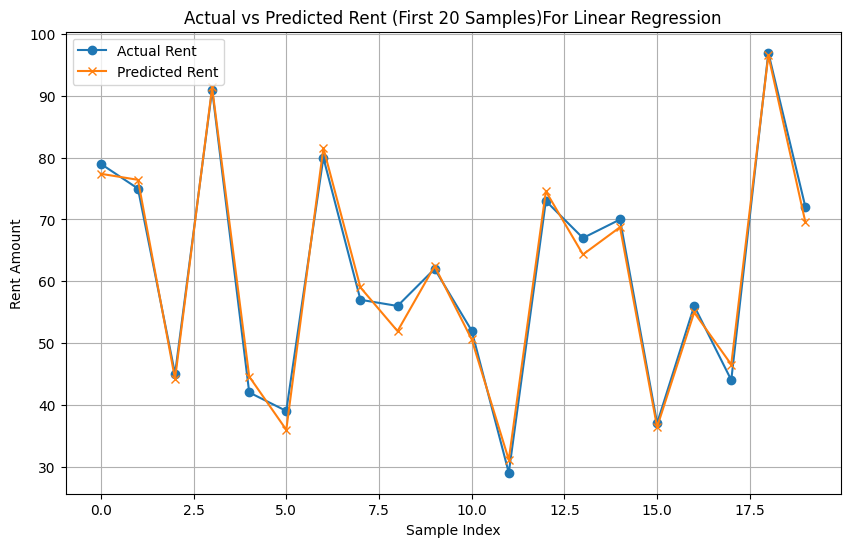

  7%|▋         | 1/15 [00:01<00:19,  1.41s/it]

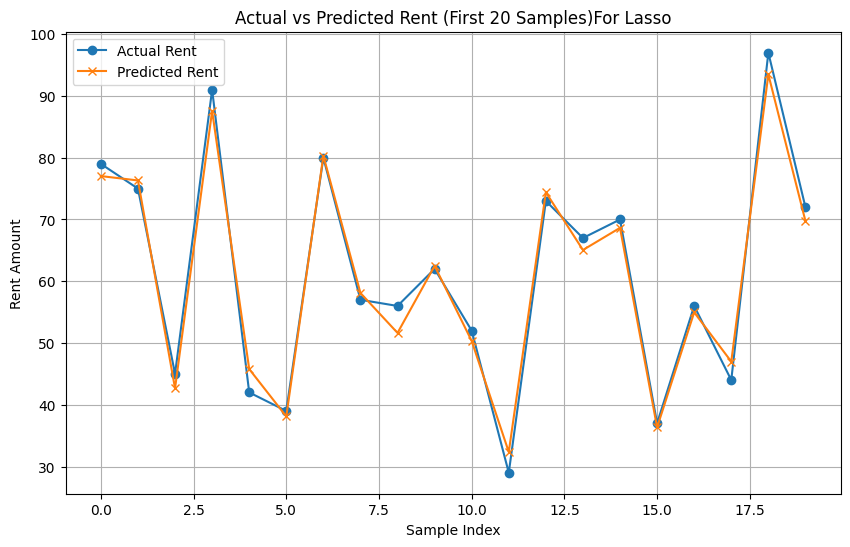

 13%|█▎        | 2/15 [00:01<00:12,  1.08it/s]

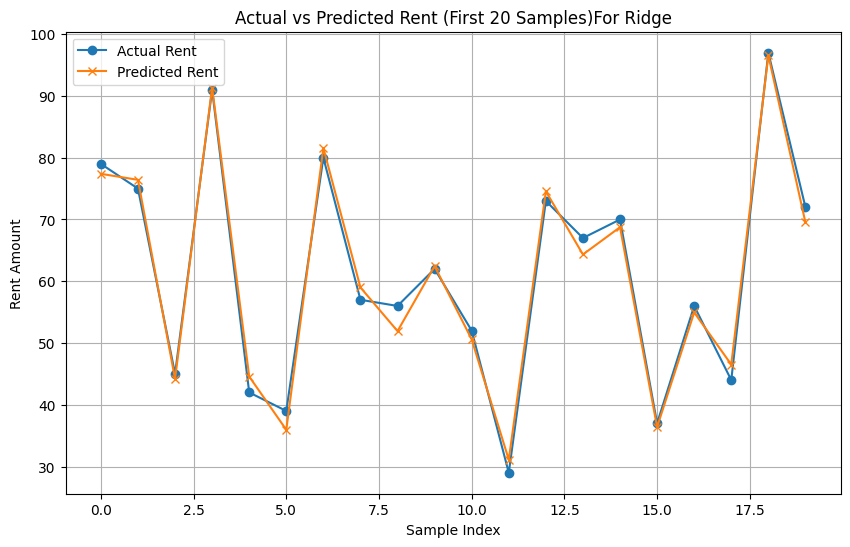

 20%|██        | 3/15 [00:02<00:09,  1.28it/s]

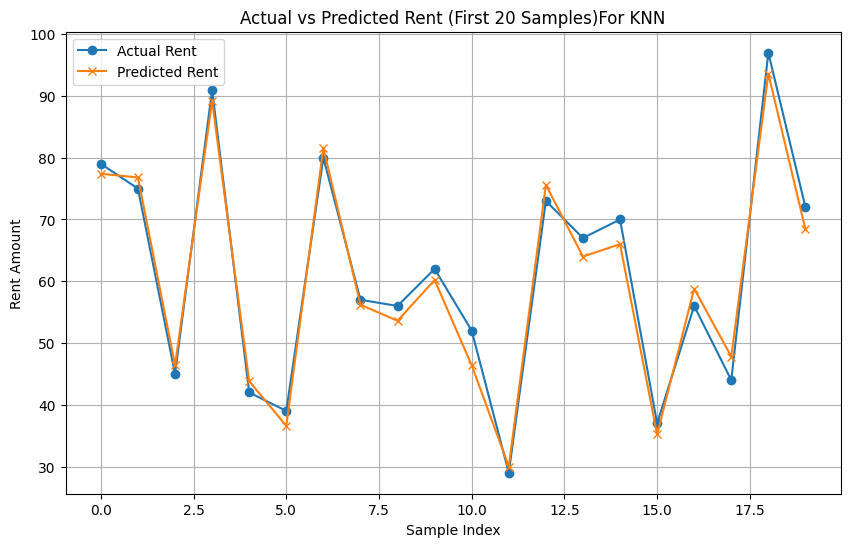

 27%|██▋       | 4/15 [00:04<00:11,  1.05s/it]

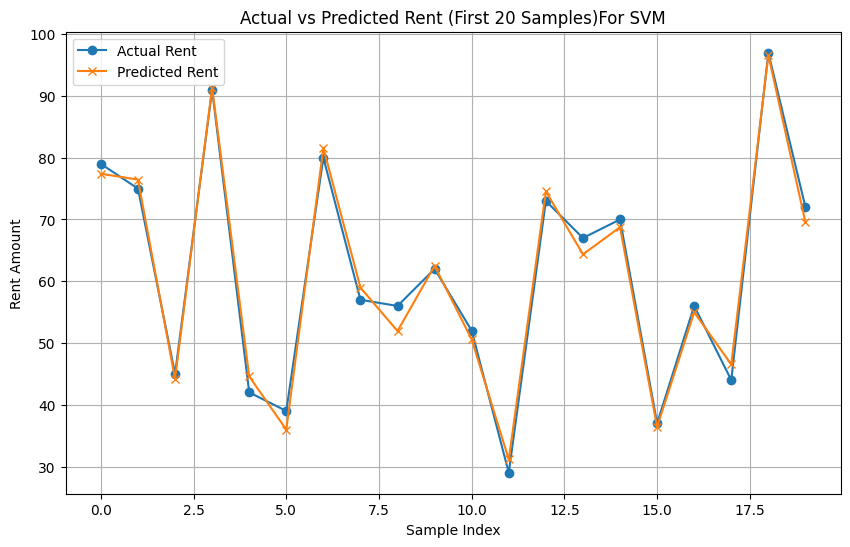

 33%|███▎      | 5/15 [00:57<03:19, 20.00s/it]

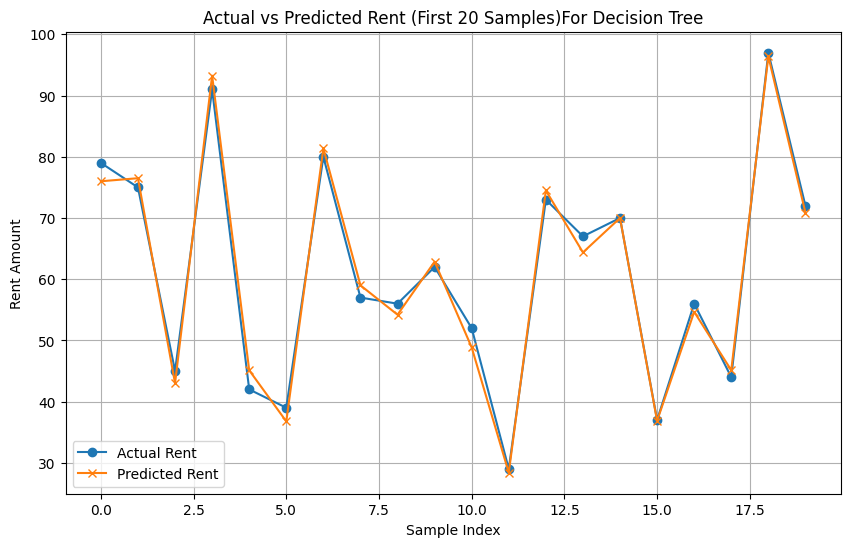

 40%|████      | 6/15 [00:57<01:59, 13.31s/it]

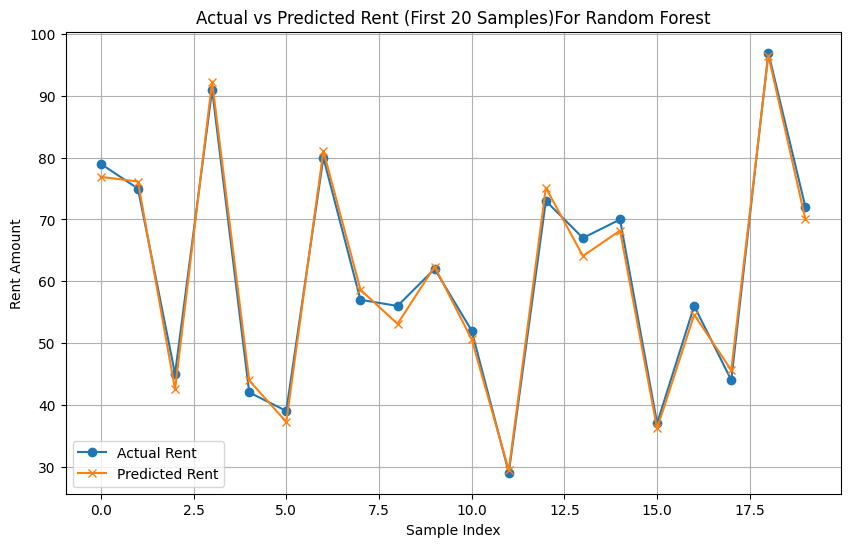

 47%|████▋     | 7/15 [00:58<01:14,  9.27s/it]

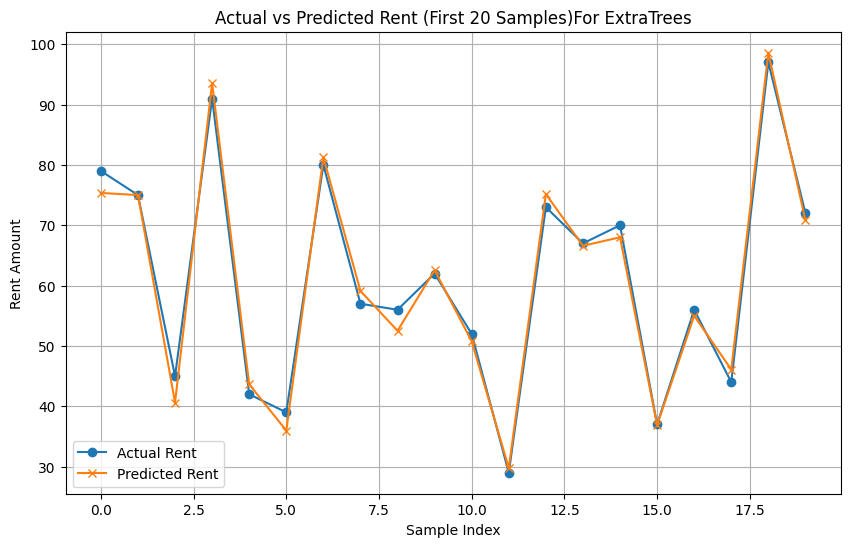

 53%|█████▎    | 8/15 [01:00<00:48,  6.97s/it]

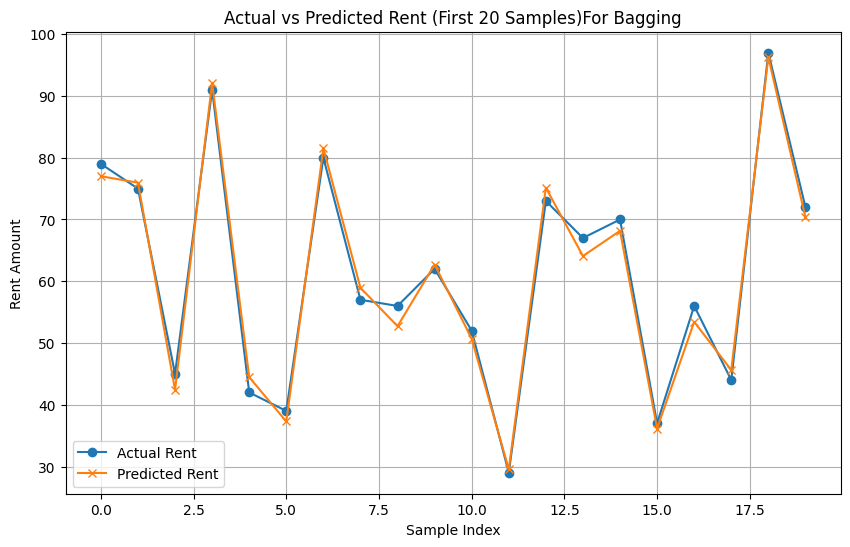

 60%|██████    | 9/15 [01:01<00:30,  5.06s/it]

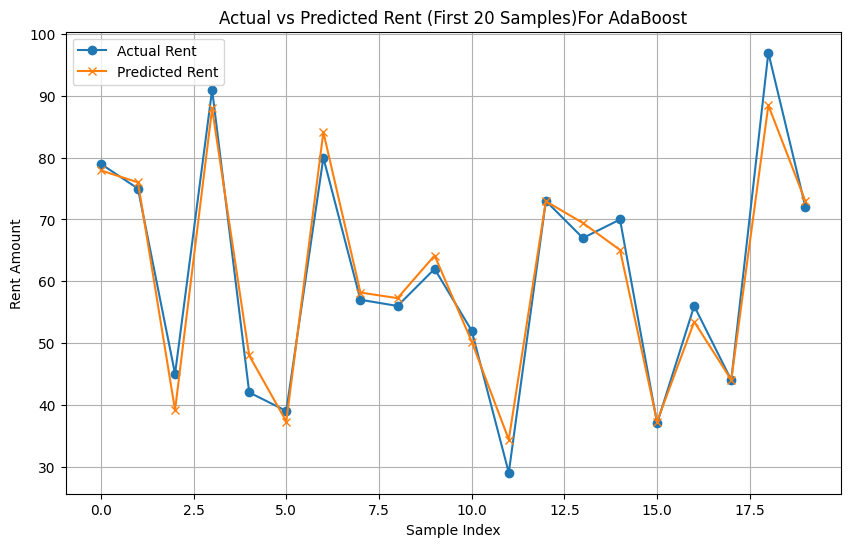

 67%|██████▋   | 10/15 [01:02<00:18,  3.61s/it]

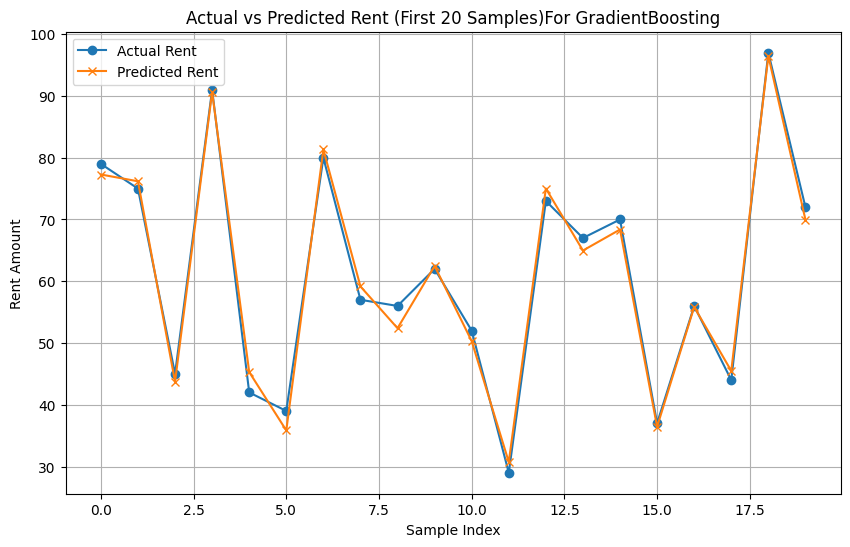

 73%|███████▎  | 11/15 [01:02<00:10,  2.71s/it]

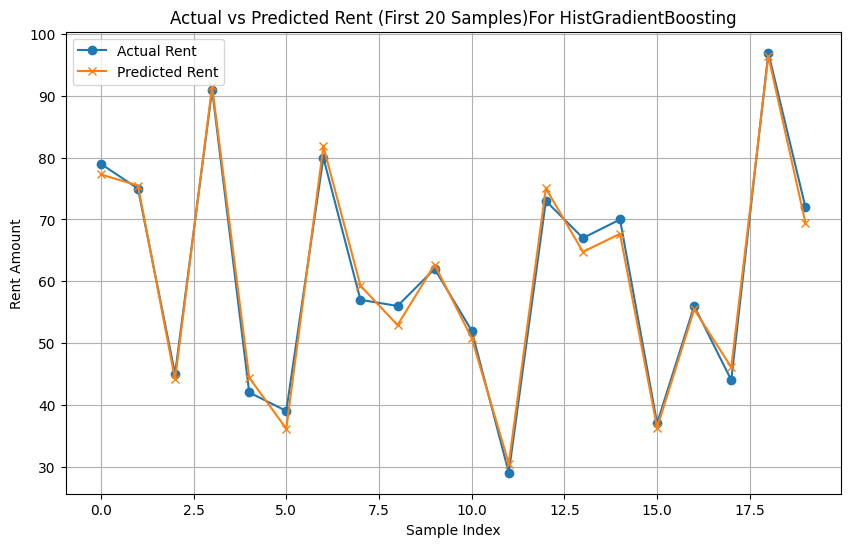

 80%|████████  | 12/15 [01:03<00:06,  2.06s/it]

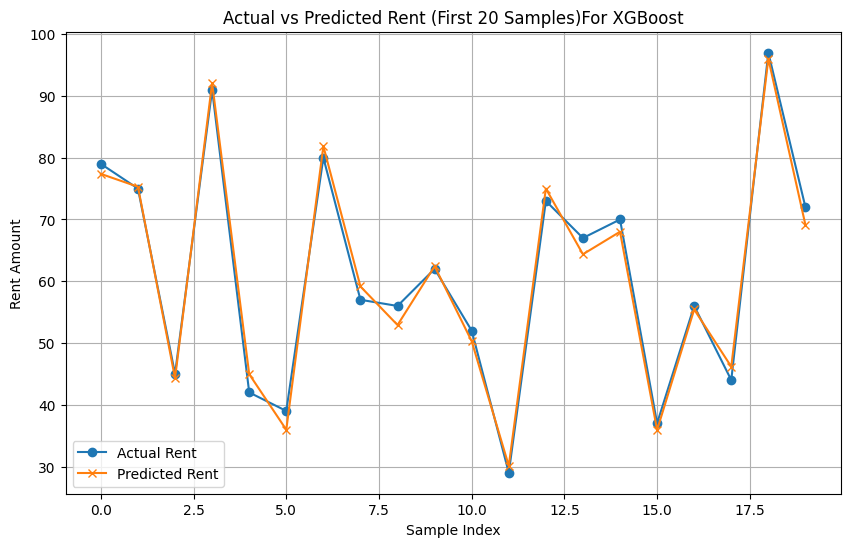

 87%|████████▋ | 13/15 [01:03<00:03,  1.55s/it]

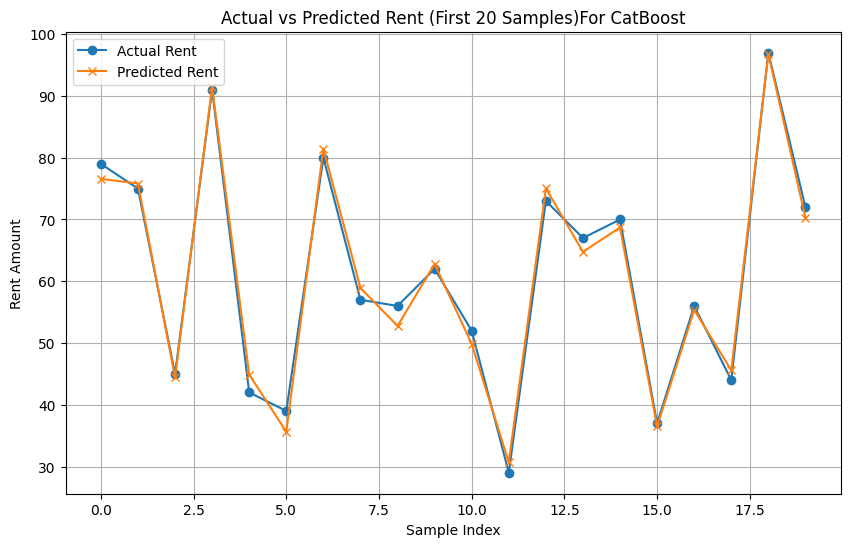

 93%|█████████▎| 14/15 [01:04<00:01,  1.21s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000549 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 92
[LightGBM] [Info] Number of data points in the train set: 7894, number of used features: 5
[LightGBM] [Info] Start training from score 55.300988


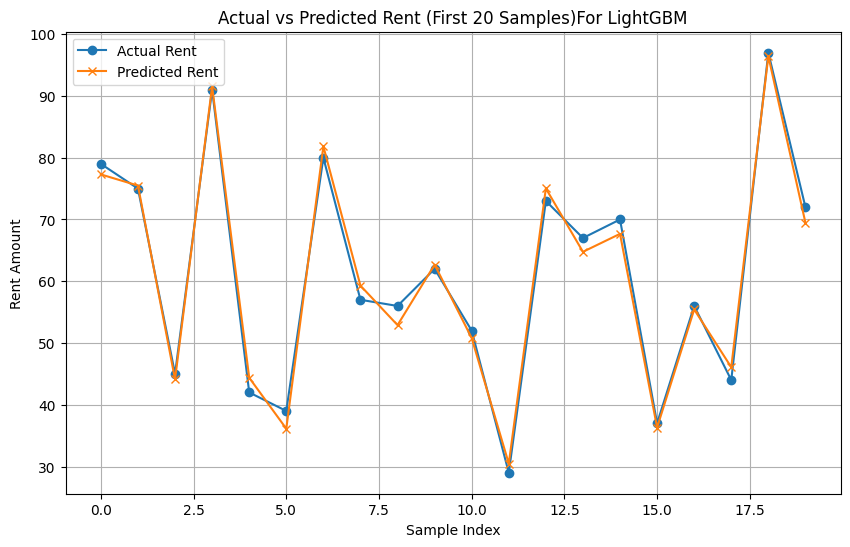

100%|██████████| 15/15 [01:04<00:00,  4.31s/it]


In [60]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(x_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, x_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, x_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(x_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [61]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(x_train, y_train)
model2.fit(x_train, y_train)
model3.fit(x_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, x_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, x_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, x_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [62]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(x_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, x_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, x_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [63]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [64]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
SVM,1.644818,1.652246,4.292569,4.306723,2.071852,2.075265,0.988306,0.988612
Linear Regression,1.644897,1.652908,4.291946,4.309834,2.071701,2.076014,0.988308,0.988604
Ridge,1.644896,1.652975,4.291952,4.310155,2.071703,2.076091,0.988308,0.988603
CatBoost,1.641885,1.721190,4.275231,4.630929,2.067663,2.151959,0.988354,0.987755
LightGBM,1.535906,1.725853,3.739956,4.646292,1.933897,2.155526,0.989812,0.987714
HistGradientBoosting,1.535906,1.725875,3.739956,4.646327,1.933897,2.155534,0.989812,0.987714
GradientBoosting,1.637777,1.723515,4.252849,4.673053,2.062244,2.161725,0.988415,0.987644
XGBoost,1.459584,1.745086,3.400142,4.774016,1.843947,2.184952,0.990737,0.987377
Stacking,1.605978,1.725853,4.306196,4.646292,2.075138,2.155526,0.988269,0.986465
Bagging,1.320329,1.830437,2.742509,5.251440,1.656052,2.291602,0.992529,0.986114


<Axes: >

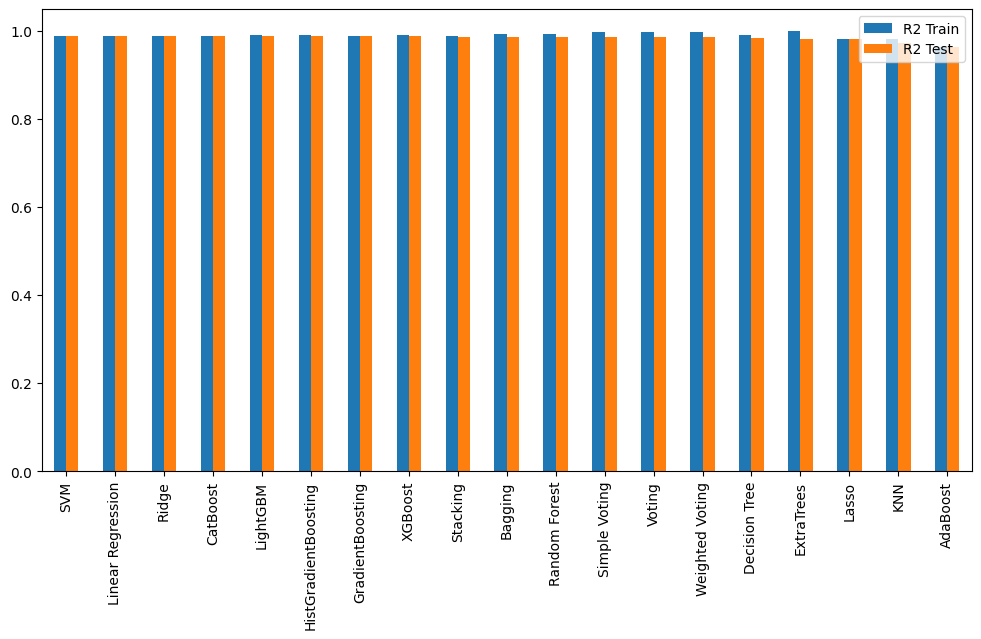

In [65]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

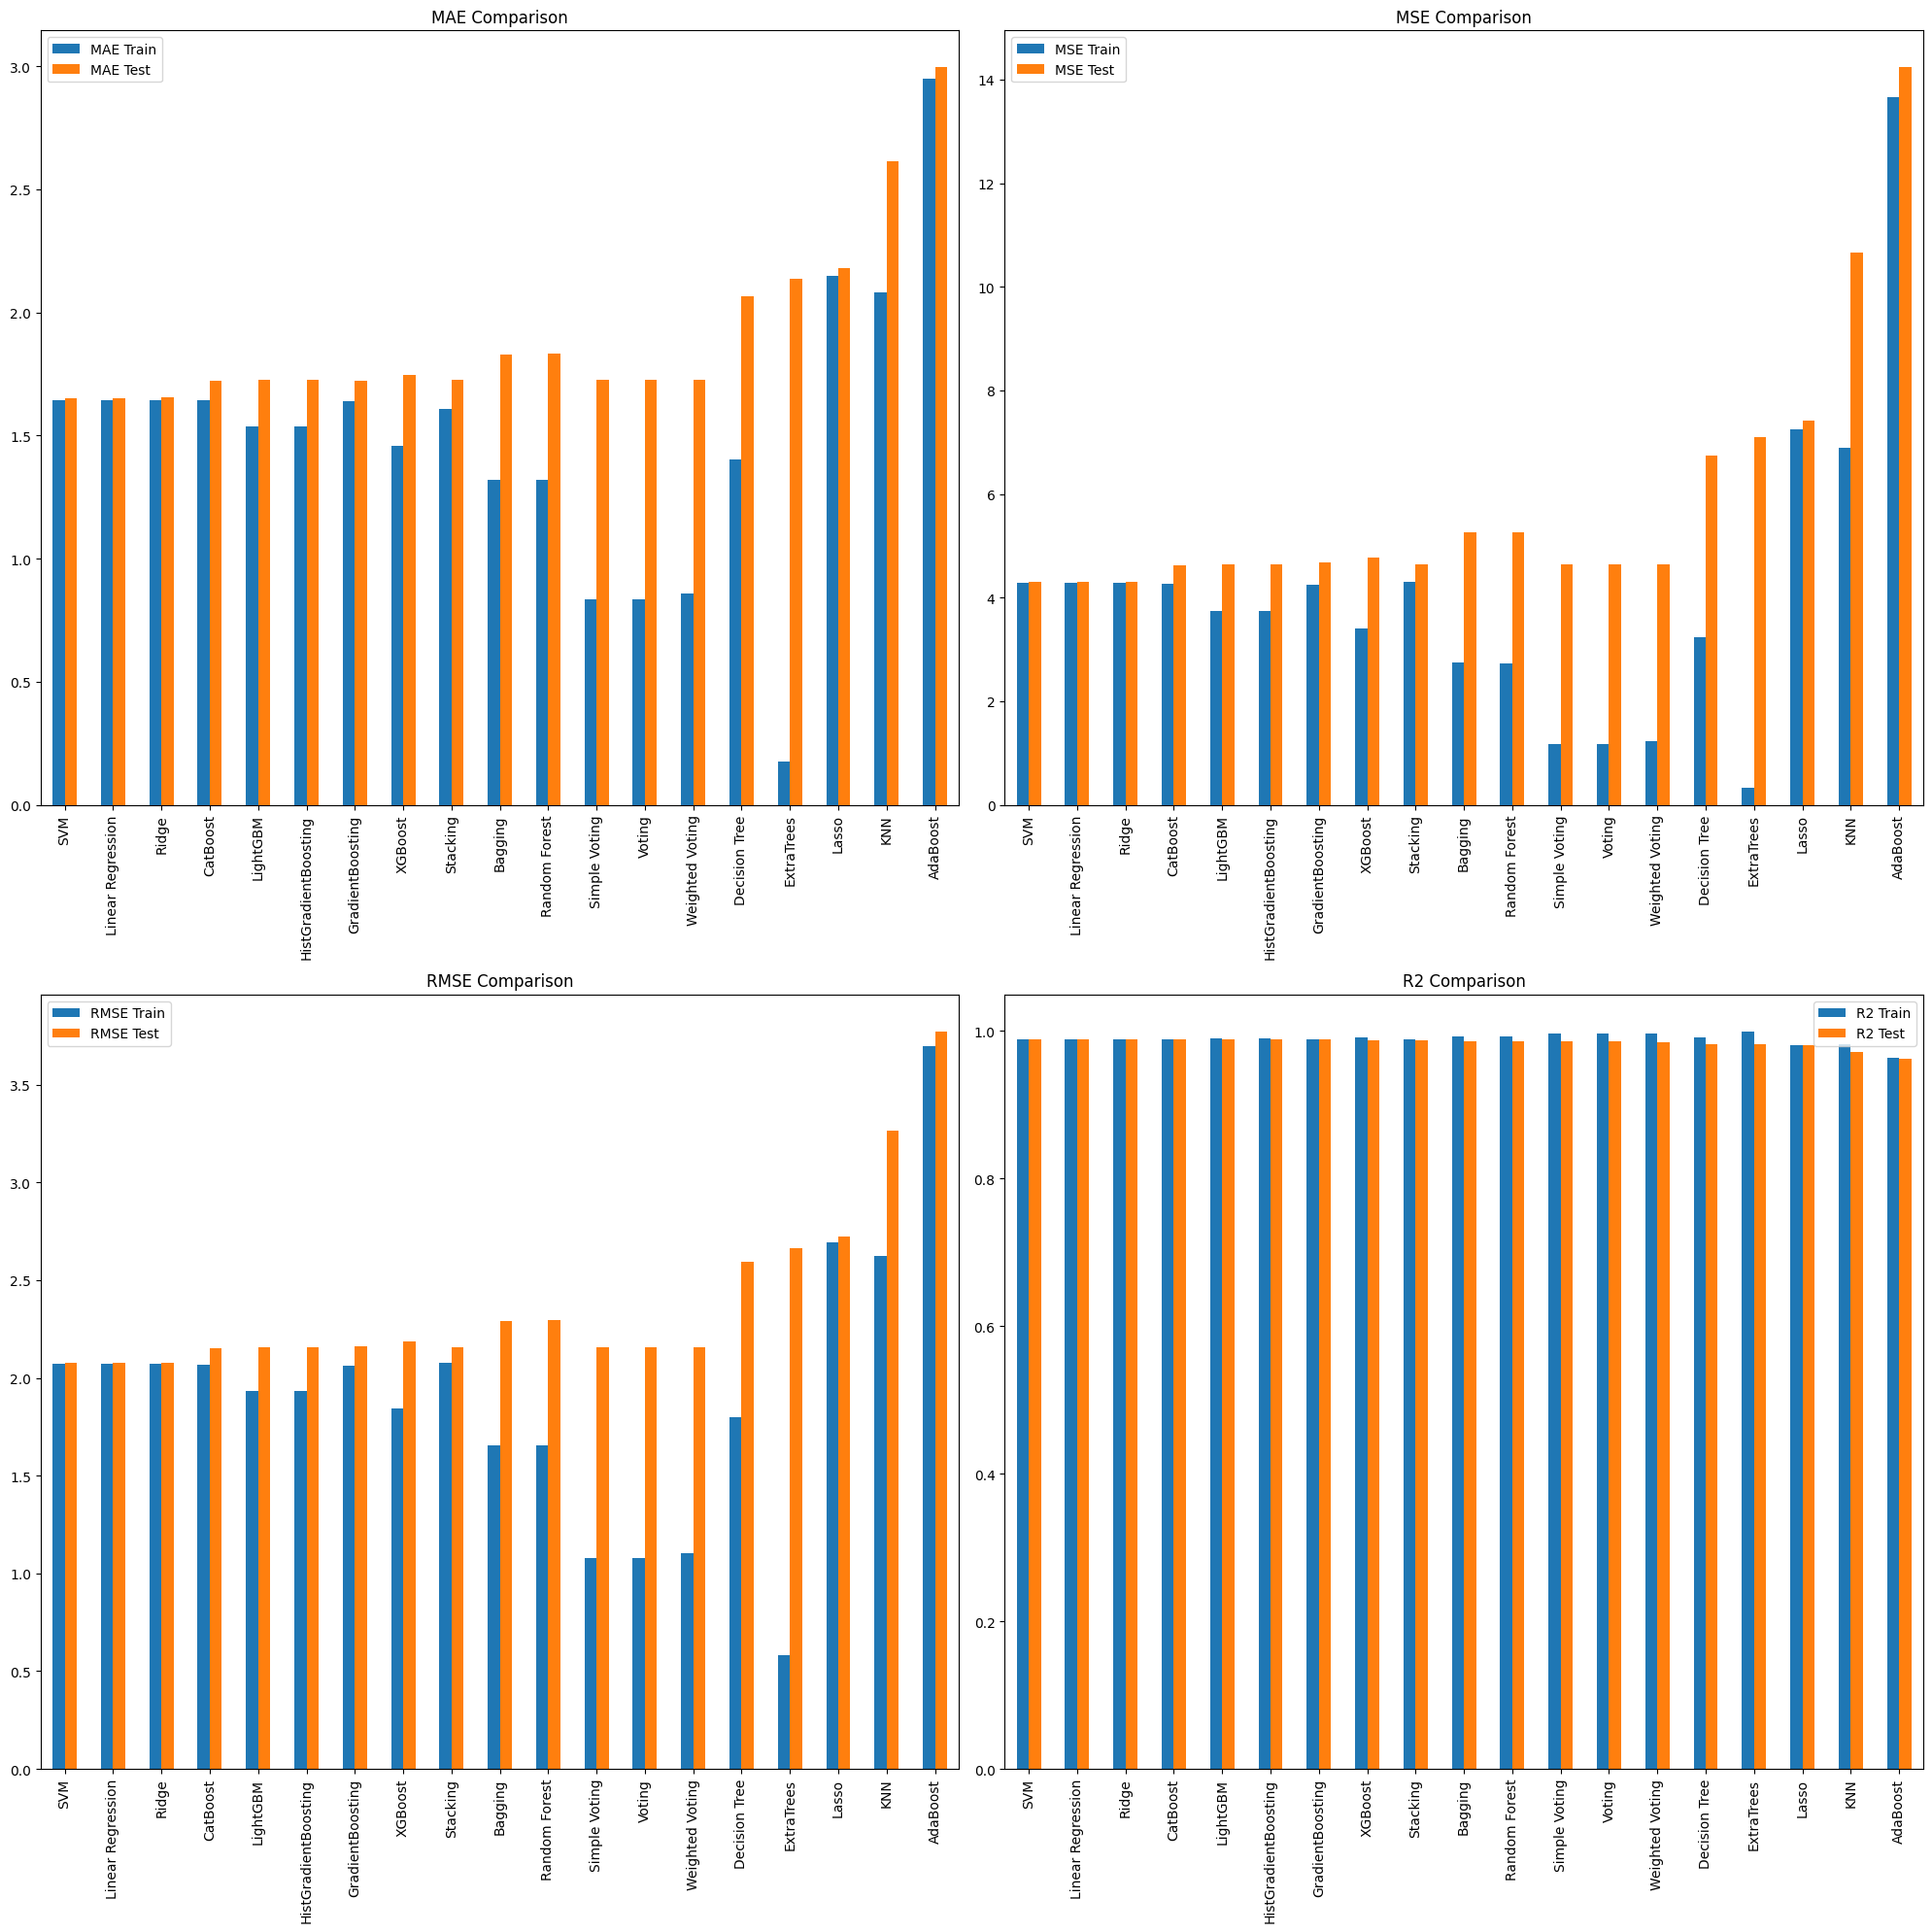

In [66]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [67]:
from sklearn.decomposition import PCA

print(x_train.shape)

pca = PCA(n_components=3,random_state=42)
x_train_pca = pca.fit_transform(x_train)
x_test_pca = pca.transform(x_test)
print(x_test_pca.shape)

(7894, 5)
(1974, 3)


<Figure size 1000x600 with 0 Axes>

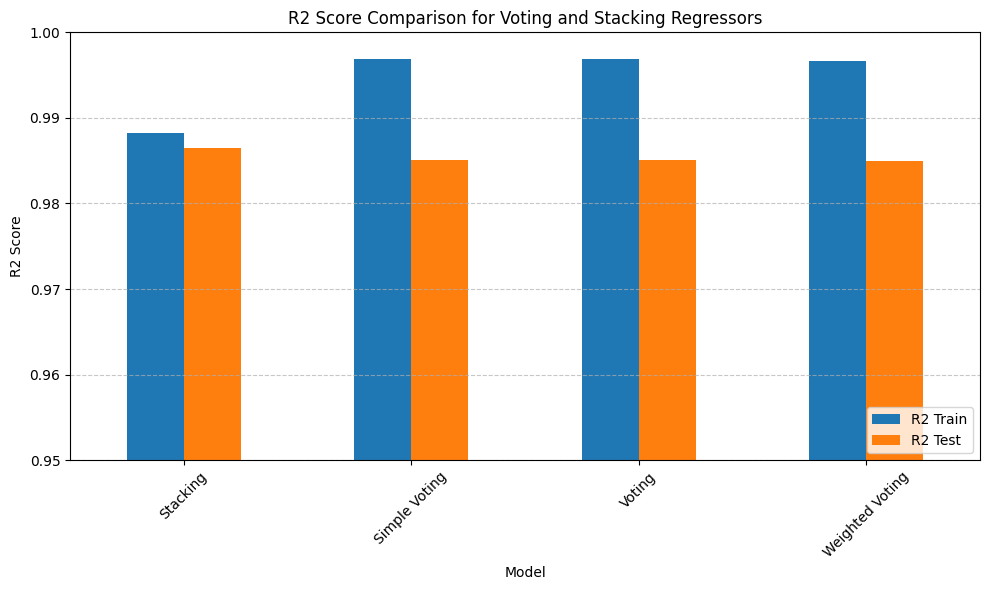

In [68]:

ensemble_models = ["Voting", "Simple Voting", "Weighted Voting", "Stacking"]
filtered_errors = errors_df.loc[errors_df.index.isin(ensemble_models)]

plt.figure(figsize=(10, 6))
filtered_errors[["R2 Train", "R2 Test"]].plot.bar(figsize=(10, 6))
plt.title("R2 Score Comparison for Voting and Stacking Regressors")
plt.ylabel("R2 Score")
plt.xlabel("Model")
plt.ylim(0.95, 1.0)
plt.legend(loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()